# 02 · Model Results & Explainability
**Main model:** composition level, extremes dropped
(`python src/train.py --level composition --drop-extremes`).

This notebook answers:
1. How good is the model, and does accuracy rise when ratings are more reliable?
2. How much would a naive random split have overstated performance?
3. Which words and features push predicted satisfaction up or down? (Ridge coefficients)
4. Which features matter most, once everything is controlled for? (SHAP on the tree model)
5. Was the EDA side-effect pattern real or confounded by therapeutic area?
6. Why did the model score one specific medicine high or low? (local explanations)

Needs: `pip install shap matplotlib`

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from train import aggregate_compositions   # same aggregation used in training

SUFFIX = "composition_net_score_noextremes"   # change if you trained another variant
TARGET = "net_score"

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

def save(name, tight=True, size=None):
    fig = plt.gcf()
    if size:
        fig.set_size_inches(*size)
    if tight:
        plt.tight_layout()
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    else:
        # SHAP waterfall plots place text outside the axes; a "tight" box would
        # stretch the image enormously, so save these at a fixed size instead.
        fig.subplots_adjust(left=0.35, right=0.95, top=0.9, bottom=0.1)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150)
    plt.show()
    plt.close(fig)   # SHAP draws on the current figure, so always start fresh

results = pd.read_csv(ROOT / "reports" / f"results_{SUFFIX}.csv")
oof = pd.read_csv(ROOT / "reports" / f"oof_{SUFFIX}.csv")
ridge = joblib.load(ROOT / "models" / f"ridge_{SUFFIX}.pkl")
gbm = joblib.load(ROOT / "models" / f"gbm_{SUFFIX}.pkl")

# Rebuild the composition table exactly as in training
bundle = pd.read_pickle(ROOT / "data" / "processed" / "features.pkl")
df = bundle["df"]
if gbm.get("drop_extremes"):
    df = df[~(df[["excellent_review", "average_review", "poor_review"]] == 100).any(axis=1)]
comp, feats = aggregate_compositions(df.reset_index(drop=True), bundle["feature_cols"], TARGET)
assert feats == gbm["feature_cols"], "Feature mismatch: re-run src/train.py after src/features.py"

print(f"{len(comp):,} compositions | {len(feats)} features | tree model: {gbm['model_type']} "
      f"| ridge alpha: {ridge['model'].alpha_}")

3,220 compositions | 169 features | tree model: sklearn_hist_gb | ridge alpha: 30


## 1. Does accuracy rise when ratings are more reliable?

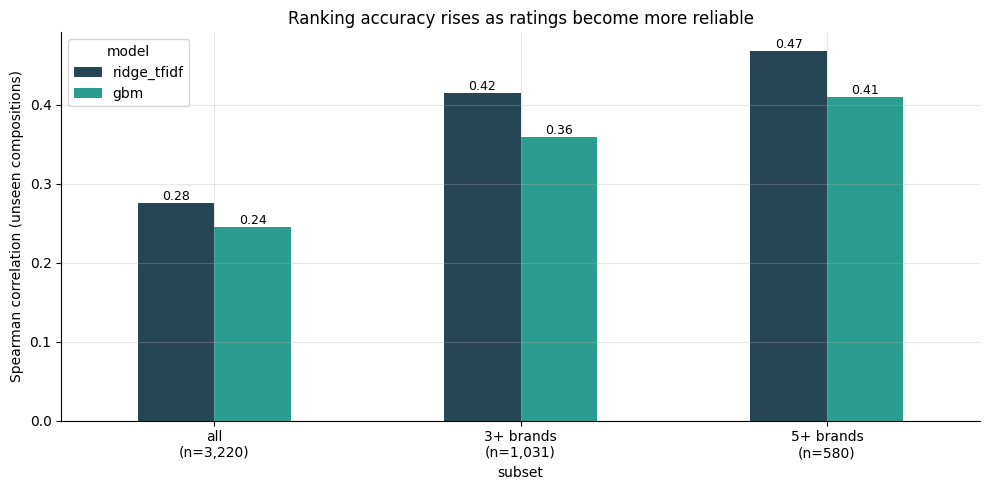

MAE                                R2                     \
model     baseline_mean     gbm ridge_tfidf baseline_mean    gbm ridge_tfidf   
subset                                                                         
3+ brands        16.158  15.571      15.044        -0.004  0.046       0.072   
5+ brands        14.708  13.800      13.522        -0.009  0.069       0.068   
all              24.037  23.341      23.003        -0.001  0.014       0.036   

               Spearman                     
model     baseline_mean    gbm ridge_tfidf  
subset                                      
3+ brands        -0.033  0.359       0.415  
5+ brands        -0.104  0.409       0.468  
all              -0.008  0.244       0.275

In [2]:
grp = results.query("split == 'grouped'")
pivot = grp.pivot(index="subset", columns="model", values="Spearman").loc[["all", "3+ brands", "5+ brands"]]
counts = grp.drop_duplicates("subset").set_index("subset")["n"].loc[pivot.index]

ax = pivot[["ridge_tfidf", "gbm"]].plot.bar(color=["#264653", "#2a9d8f"], rot=0)
ax.set_xticklabels([f"{s}\n(n={n:,})" for s, n in counts.items()])
ax.set_ylabel("Spearman correlation (unseen compositions)")
ax.set_title("Ranking accuracy rises as ratings become more reliable")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=9)
save("09_accuracy_by_reliability")

grp.pivot(index="subset", columns="model", values=["MAE", "R2", "Spearman"]).round(3)

**Read:** compositions sold by more brands have averaged, less noisy ratings. If the model's
accuracy rises on them, the low overall score is mainly noise in the target, not a weak model.

## 2. How much would a random split have overstated performance?

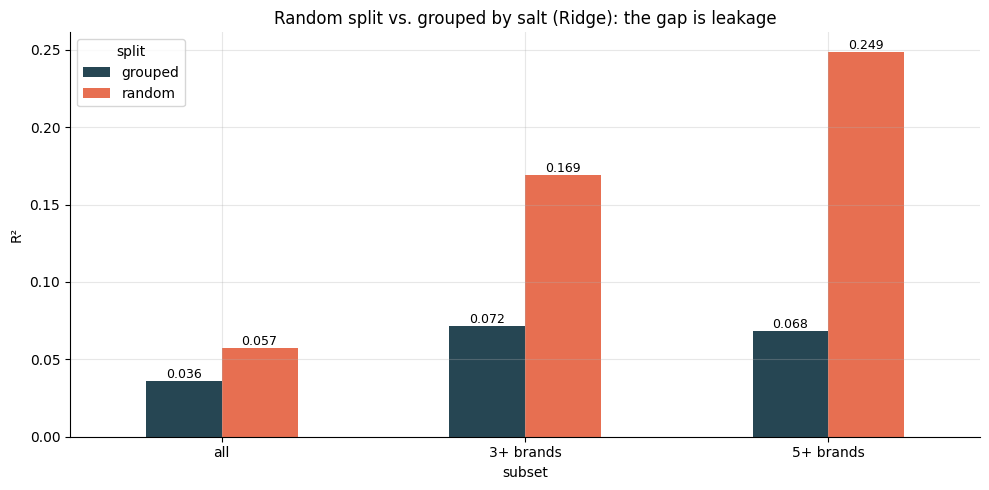

split,grouped,random,inflation_x
subset,,,
all,0.036,0.057,1.6
3+ brands,0.072,0.169,2.4
5+ brands,0.068,0.249,3.6


In [3]:
cmp = (results.query("model == 'ridge_tfidf'")
         .pivot(index="subset", columns="split", values="R2")
         .loc[["all", "3+ brands", "5+ brands"]])
ax = cmp[["grouped", "random"]].plot.bar(color=["#264653", "#e76f51"], rot=0)
ax.set_ylabel("R²")
ax.set_title("Random split vs. grouped by salt (Ridge): the gap is leakage")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=9)
save("10_random_vs_grouped")
cmp["inflation_x"] = (cmp["random"] / cmp["grouped"].where(cmp["grouped"] > 0)).round(1)
cmp.round(3)

**Why:** with a random split, Paracetamol 500mg can be in training while Paracetamol 650mg is in
the test set, so the model "recognises" the molecule. Grouping by salt combination removes that shortcut.

## 3. Predicted vs. actual (out-of-fold, reliable compositions)

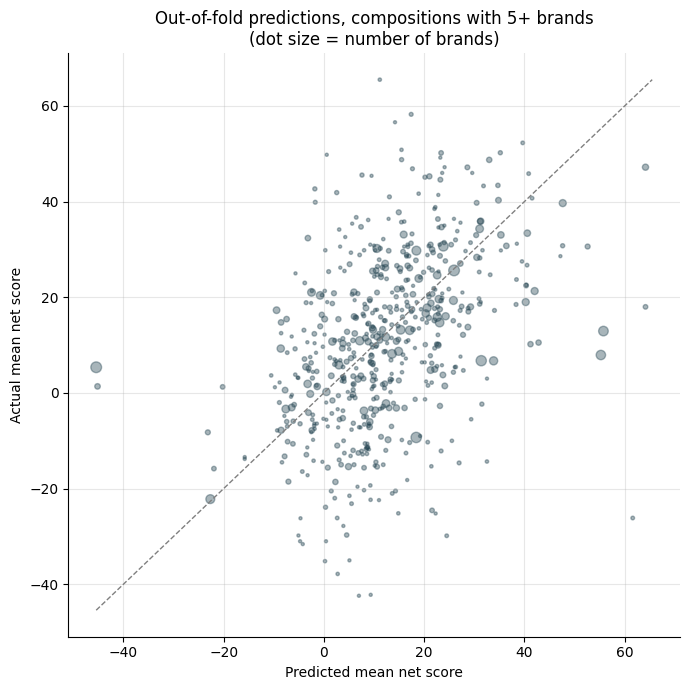

,mean,count
pred_quintile,,
Q1 lowest,1.3,116
Q2,2.7,116
Q3,9.3,116
Q4,17.3,116
Q5 highest,22.7,116


In [4]:
pred_col = "pred_ridge_tfidf_grouped"
sub = oof[oof["n_brands"] >= 5]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(sub[pred_col], sub[TARGET], s=np.clip(sub["n_brands"], 5, 60), alpha=0.4, color="#264653")
lims = [min(sub[pred_col].min(), sub[TARGET].min()), max(sub[pred_col].max(), sub[TARGET].max())]
ax.plot(lims, lims, "--", color="gray", lw=1)
ax.set_xlabel("Predicted mean net score")
ax.set_ylabel("Actual mean net score")
ax.set_title("Out-of-fold predictions, compositions with 5+ brands\n(dot size = number of brands)")
save("11_pred_vs_actual")

# Ranking quality in plain words: does the top predicted quintile really score higher?
sub = sub.assign(pred_quintile=pd.qcut(sub[pred_col], 5, labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"]))
sub.groupby("pred_quintile", observed=True)[TARGET].agg(["mean", "count"]).round(1)

## 4. Ridge: which words and features push ratings up or down?
Coefficients are learned with everything else held constant, so they are cleaner than the raw EDA gaps.

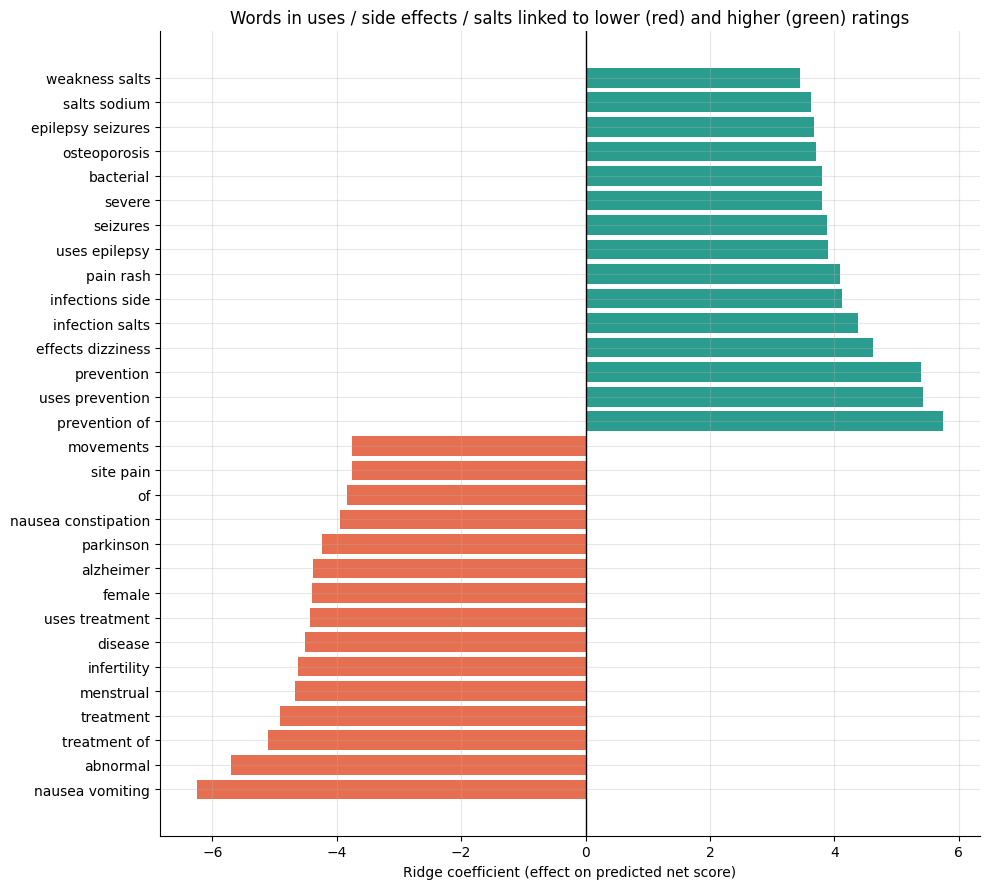

In [5]:
vocab = ridge["tfidf"].get_feature_names_out()
names = np.concatenate([["text: " + v for v in vocab], ["feat: " + f for f in ridge["feature_cols"]]])
coefs = pd.Series(ridge["model"].coef_, index=names)

# Only show text terms used by at least 20 compositions, to avoid one-off words
X_text = ridge["tfidf"].transform(comp["text"])
doc_freq = pd.Series(np.asarray((X_text > 0).sum(axis=0)).ravel(), index="text: " + vocab)
text_coefs = coefs[coefs.index.str.startswith("text: ")]
text_coefs = text_coefs[doc_freq.reindex(text_coefs.index).fillna(0) >= 20]

top = pd.concat([text_coefs.nsmallest(15), text_coefs.nlargest(15)])
colors = ["#e76f51" if v < 0 else "#2a9d8f" for v in top]
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top.index.str.replace("text: ", ""), top.values, color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Ridge coefficient (effect on predicted net score)")
ax.set_title("Words in uses / side effects / salts linked to lower (red) and higher (green) ratings")
save("12_ridge_text_terms")

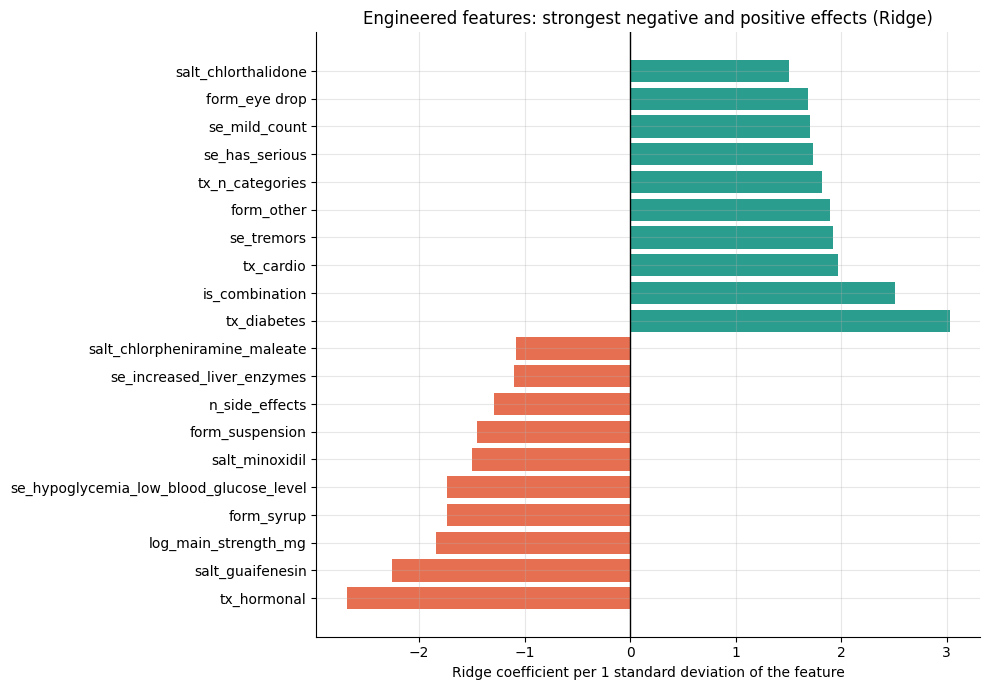

In [6]:
feat_coefs = coefs[coefs.index.str.startswith("feat: ")]
top_f = pd.concat([feat_coefs.nsmallest(10), feat_coefs.nlargest(10)])
colors = ["#e76f51" if v < 0 else "#2a9d8f" for v in top_f]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_f.index.str.replace("feat: ", ""), top_f.values, color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Ridge coefficient per 1 standard deviation of the feature")
ax.set_title("Engineered features: strongest negative and positive effects (Ridge)")
save("13_ridge_features")

## 5. SHAP on the tree model: what matters most overall?

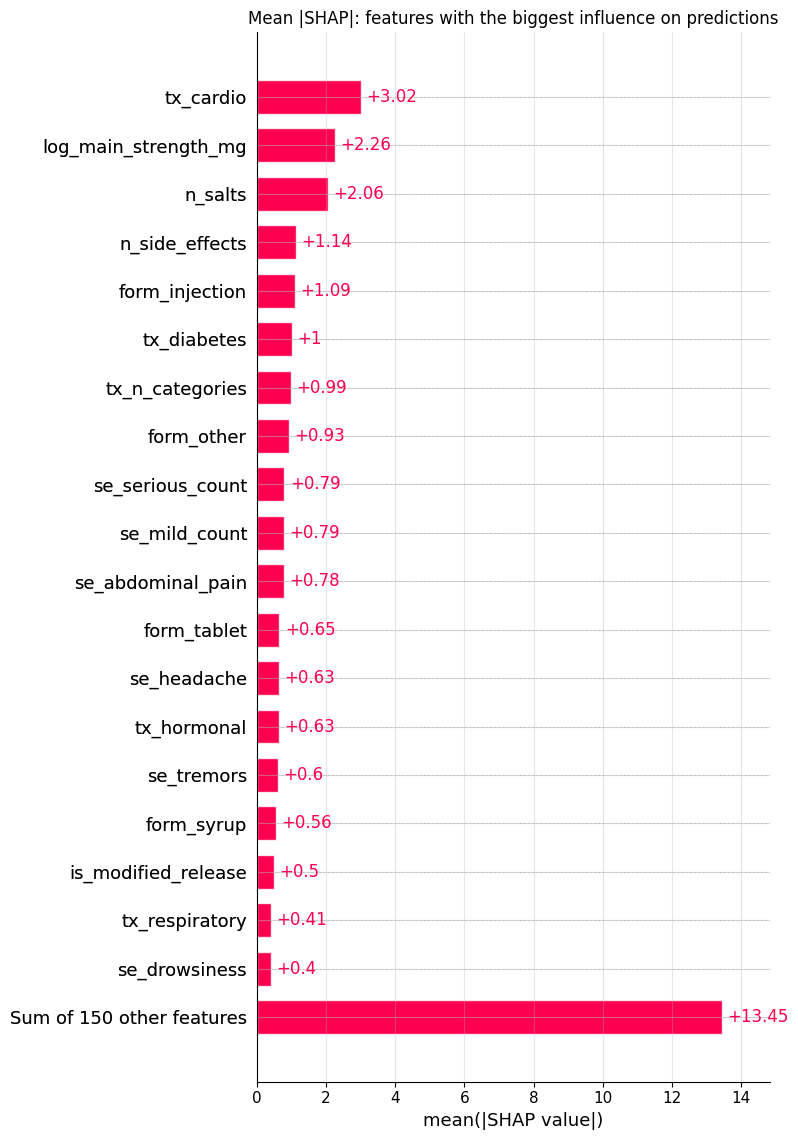

In [7]:
X = comp[feats].astype("float64")
explainer = shap.TreeExplainer(gbm["model"])
shap_values = explainer.shap_values(X)
expl = shap.Explanation(values=shap_values, base_values=np.full(len(X), explainer.expected_value),
                        data=X.values, feature_names=feats)

shap.plots.bar(expl, max_display=20, show=False)
plt.title("Mean |SHAP|: features with the biggest influence on predictions")
save("14_shap_importance")

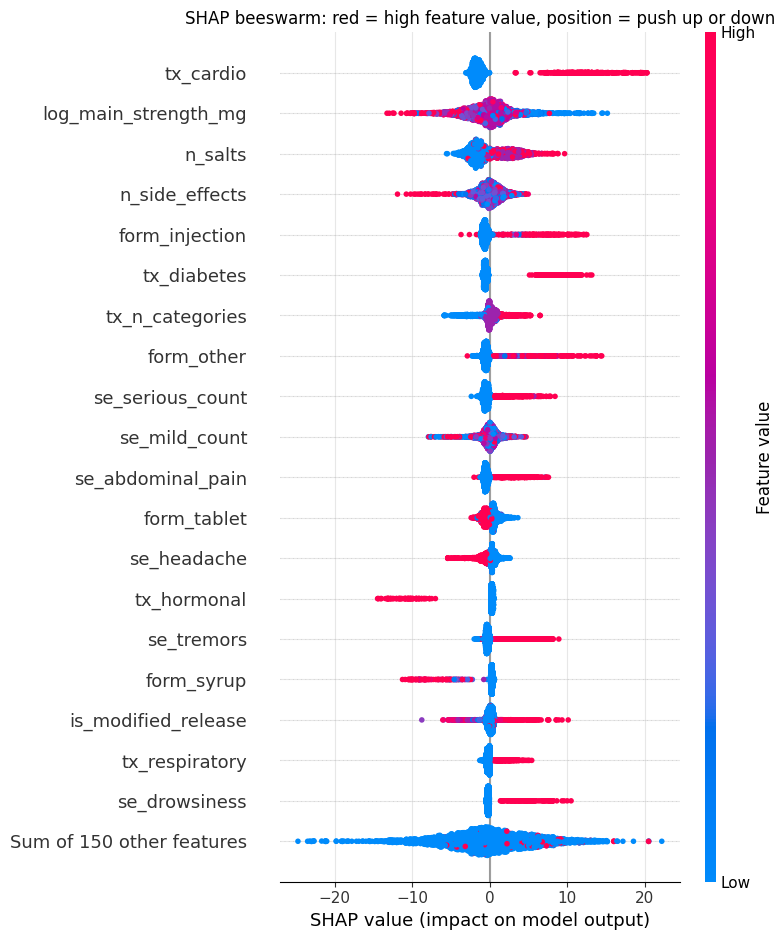

In [8]:
shap.plots.beeswarm(expl, max_display=20, show=False)
plt.title("SHAP beeswarm: red = high feature value, position = push up or down")
save("15_shap_beeswarm")

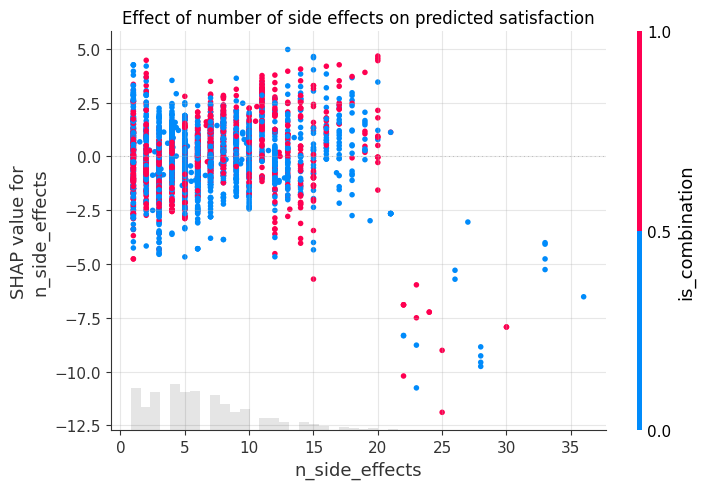

In [9]:
# How the number of side effects affects predictions, coloured by whether it's a combination drug
if "n_side_effects" in feats:
    shap.plots.scatter(expl[:, "n_side_effects"], color=expl[:, "is_combination"]
                       if "is_combination" in feats else None, show=False)
    plt.title("Effect of number of side effects on predicted satisfaction")
    save("16_shap_n_side_effects")

## 6. Was the EDA side-effect pattern real or confounded?
In the EDA, cardio side effects (ankle swelling, slow heart rate) looked "good" and skin side
effects looked "bad". If that was mainly the therapeutic area, the model should give the
**area** a large effect and the **side effect itself** a small one.

In [10]:
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=feats)
check = [f for f in ["tx_cardio", "tx_skin", "tx_antifungal", "tx_hormonal",
                     "se_ankle_swelling", "se_slow_heart_rate", "se_skin_peeling",
                     "se_dry_skin", "se_hair_loss", "form_cream"] if f in feats]

table = pd.DataFrame({
    "raw_gap_in_data": [comp.loc[comp[f] > 0, TARGET].mean() - comp.loc[comp[f] == 0, TARGET].mean()
                        for f in check],
    "model_mean_abs_shap": mean_abs[check].values,
}, index=check).round(2)
table["kind"] = ["therapeutic area / form" if f.startswith(("tx_", "form_")) else "side effect" for f in check]
table.sort_values("model_mean_abs_shap", ascending=False)

,raw_gap_in_data,model_mean_abs_shap,kind
tx_cardio,16.10,3.02,therapeutic area / form
tx_hormonal,-14.12,0.63,therapeutic area / form
se_dry_skin,-13.98,0.33,side effect
form_cream,-8.27,0.32,therapeutic area / form
se_hair_loss,-12.24,0.22,side effect
tx_antifungal,-8.08,0.18,therapeutic area / form
se_slow_heart_rate,17.99,0.15,side effect
tx_skin,-5.80,0.14,therapeutic area / form
se_skin_peeling,-10.63,0.06,side effect
se_ankle_swelling,23.14,0.00,side effect


**Read:** a big raw gap but a small SHAP value means the pattern was mostly explained by
something else (usually the therapeutic area or dosage form).

## 7. Local explanations: why did the model score these compositions?

  File "c:\Users\Rupes\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Rupes\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Rupes\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Rupes\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


HIGHEST predicted: fluticasone propionate (500mcg) + salmeterol (50mcg)  |  5 brands  |  actual 46.0  |  predicted 46.2


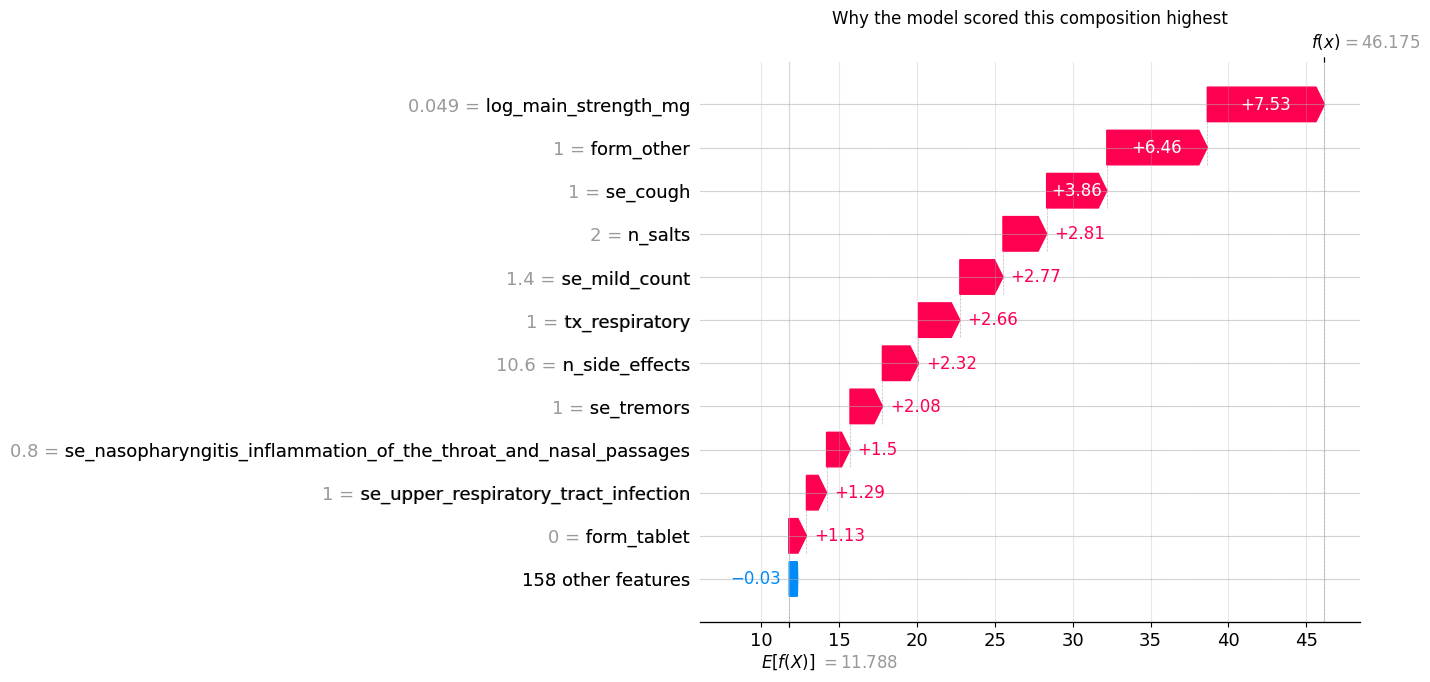

LOWEST predicted: oxetacaine (20mg) + sucralfate (1000mg)  |  6 brands  |  actual -37.8  |  predicted -28.3


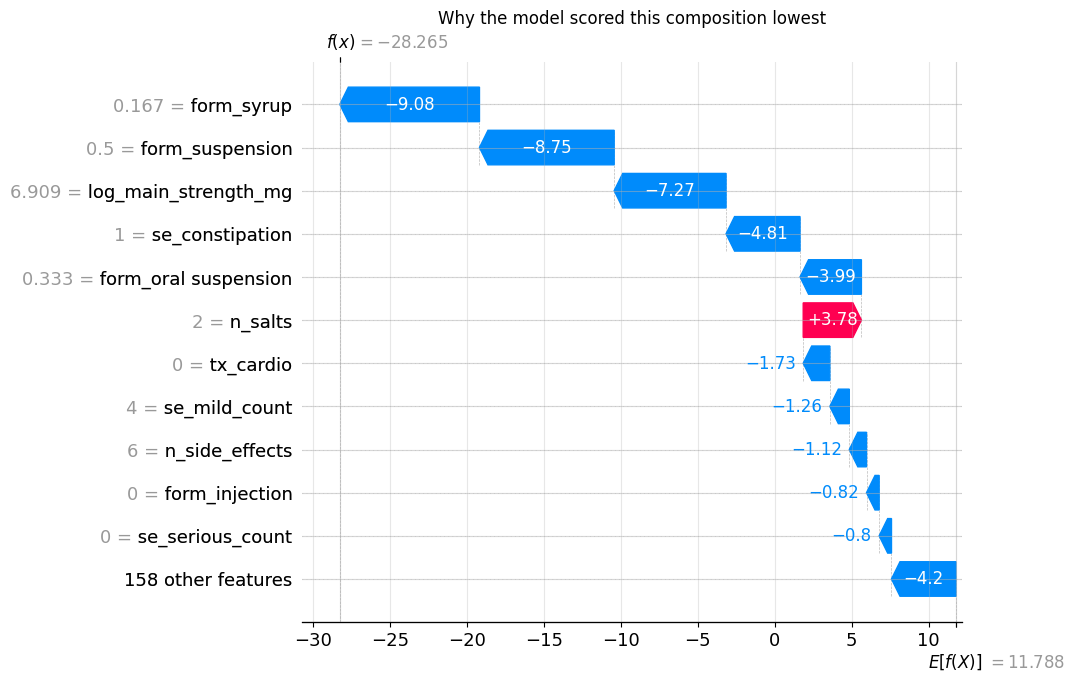

In [11]:
reliable = comp.index[comp["n_brands"] >= 5]
preds = gbm["model"].predict(X)
hi = reliable[np.argmax(preds[reliable])]
lo = reliable[np.argmin(preds[reliable])]

for idx, label in [(hi, "highest"), (lo, "lowest")]:
    row = comp.loc[idx]
    print(f"{label.upper()} predicted: {row['composition_clean']}  |  "
          f"{row['n_brands']} brands  |  actual {row[TARGET]:.1f}  |  predicted {preds[idx]:.1f}")
    shap.plots.waterfall(expl[idx], max_display=12, show=False)
    plt.title(f"Why the model scored this composition {label}")
    save(f"17_waterfall_{label}", tight=False, size=(11, 7))

In [12]:
# Look up any composition by keyword
QUERY = "telmisartan"
hits = comp[comp["composition_clean"].str.contains(QUERY, case=False)].copy()
hits["predicted"] = gbm["model"].predict(hits[feats].astype("float64"))
hits[["composition_clean", "n_brands", TARGET, "predicted", "primary_category"]] \
    .sort_values("n_brands", ascending=False).head(10).round(1)

,composition_clean,n_brands,net_score,predicted,primary_category
3024,telmisartan (40mg),47,30.7,28.6,cardio
296,amlodipine (5mg) + telmisartan (40mg),41,29.8,29.3,cardio
1792,hydrochlorothiazide (12.5mg) + telmisartan (40mg),31,34.3,34.2,cardio
3023,telmisartan (20mg),27,16.0,17.6,cardio
2323,metoprolol succinate (50mg) + telmisartan (40mg),26,19.0,24.6,cardio
2317,metoprolol succinate (25mg) + telmisartan (40mg),22,33.4,30.1,cardio
906,chlorthalidone (12.5mg) + telmisartan (40mg),21,35.9,33.6,cardio
283,amlodipine (5mg) + hydrochlorothiazide (12.5mg...,16,30.8,30.5,cardio
3025,telmisartan (80mg),14,17.5,21.2,cardio
1793,hydrochlorothiazide (12.5mg) + telmisartan (80mg),13,33.0,34.5,cardio


## Key findings (fill in from your numbers)
- **Noise ceiling:** brand-level ratings are mostly noise (median 1 brand per composition, no review counts).
- **Reliability effect:** Spearman rises from ___ (all) to ___ (5+ brands) on unseen compositions.
- **Leakage:** a random split would have overstated R² by about ___x.
- **Biggest drivers (SHAP):** …
- **Confounding:** side effects like ankle swelling look positive only because they belong to cardio drugs; the model attributes the effect to ___.
- **Limitations:** ratings ≠ clinical effectiveness; scraped snapshot from one platform; no review counts.

**Next:** `app.py`, the Streamlit app.